# Smartventory — Inventory Intelligence & Stock Prediction (Notebook 01)
End-to-end weekly demand forecasting and inventory intelligence prototype built on reusable `backend` modules.
- **Scope**: Data validation, `W-SUN` cross-store aggregation, 4-week moving-average baseline, leakage-safe `RandomForestRegressor`, multi-horizon forecasting, split-conformal uncertainty, inventory analysis, stockout risk, and indicative replenishment.
- **Dataset Disclosure**: `sales_data.csv` is synthetic retail data; results demonstrate prototype behavior rather than live shop validation.

## 2. Imports and Configuration
Configure repository path, plotting defaults, data paths, and import reusable `backend` pipeline modules.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from backend.models.demand_forecaster import (
    DEFAULT_RF_PARAMS,
    compute_moving_average_baseline,
    train_random_forest,
    predict_random_forest,
)
from backend.services import (
    load_csv,
    validate_or_raise,
    preprocess_dataframe,
    aggregate_weekly_demand,
    inspect_weekly_continuity,
    FEATURE_COLUMNS,
    build_product_mapping,
    build_lag_and_calendar_features,
    chronological_week_split,
    evaluate_regression_metrics,
    compare_models,
    evaluate_by_product,
    calibrate_conformal_interval,
    evaluate_interval_coverage,
    forecast_future_weeks,
    evaluate_recursive_horizons,
    verify_inventory_semantics,
    analyze_product_inventory,
    summarize_category_inventory,
    generate_replenishment_recommendations,
)

DATA_PATH = 'sales_data.csv'
WEEKLY_EXPORT_PATH = 'weekly_product_demand.csv'
HORIZON_OPTIONS = (1, 2, 3, 4, 8)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 110
print('Imports and backend modules loaded successfully.')

Imports and backend modules loaded successfully.


## 3. Dataset Loading and Validation
Load `sales_data.csv` via `load_csv` and enforce schema/quality checks via `validate_or_raise`.

In [2]:
raw_df = load_csv(DATA_PATH)
validation_report = validate_or_raise(raw_df)

print(f"Loaded '{DATA_PATH}': {raw_df.shape[0]:,} rows x {raw_df.shape[1]} columns")
print(f"Validation passed: {validation_report['is_valid']} | Duplicate rows: {validation_report['duplicate_rows']} | Duplicate (Prod,Store,Date): {validation_report['duplicate_triplets']}")
print(f"Products: {validation_report['metrics']['unique_products']} | Stores: {validation_report['metrics']['unique_stores']} | Unique dates: {validation_report['metrics']['unique_dates']}")
display(raw_df.head())

Loaded 'sales_data.csv': 76,000 rows x 16 columns
Validation passed: True | Duplicate rows: 0 | Duplicate (Prod,Store,Date): 0
Products: 20 | Stores: 5 | Unique dates: 760


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


## 4. Data Preprocessing
Apply documented datetime conversion, numeric validation, whitespace trimming, and chronological sorting via `preprocess_dataframe`.

In [3]:
processed_df = preprocess_dataframe(raw_df)
print(f"Date range: {processed_df['Date'].min().strftime('%Y-%m-%d')} to {processed_df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Chronologically sorted: {processed_df['Date'].is_monotonic_increasing}")
display(processed_df[['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Competitor Pricing', 'Demand']].describe().T)

Date range: 2022-01-01 to 2024-01-30
Chronologically sorted: True


,count,mean,std,min,25%,50%,75%,max
Inventory Level,76000.0,301.062842,226.510161,0.00,136.0000,227.0,408.0000,2267.00
Units Sold,76000.0,88.827316,43.994525,0.00,58.0000,84.0,114.0000,426.00
Units Ordered,76000.0,89.090645,162.404627,0.00,0.0000,0.0,121.0000,1616.00
Price,76000.0,67.726028,39.377899,4.74,31.9975,64.5,95.8300,228.03
Discount,76000.0,9.087039,7.475781,0.00,5.0000,10.0,10.0000,25.00
Competitor Pricing,76000.0,69.454029,40.943818,4.29,32.6200,65.7,97.9325,261.22
Demand,76000.0,104.317158,46.964801,4.00,71.0000,100.0,133.0000,430.00


## 5. Weekly Demand Aggregation
Aggregate daily `Demand` across all stores per `Product ID` into Sunday-ending calendar weeks (`W-SUN`), disclose partial boundary weeks, and export `weekly_product_demand.csv`.

In [4]:
weekly_df = aggregate_weekly_demand(processed_df)
continuity = inspect_weekly_continuity(weekly_df, raw_df=processed_df)

print(f"Weekly shape: {continuity['row_count']:,} rows ({continuity['unique_products']} products x {continuity['unique_weeks']} weeks)")
print(f"Week range: {continuity['week_start']} to {continuity['week_end']} | Gaps detected: {continuity['has_gaps']}")
print(f"Partial-week disclosure: first week has {continuity['first_week_days']} active days; last week has {continuity['last_week_days']} active days.")

weekly_df.to_csv(WEEKLY_EXPORT_PATH, index=False)
print(f"Exported weekly demand to '{WEEKLY_EXPORT_PATH}'")
display(weekly_df.head(8))

Weekly shape: 2,200 rows (20 products x 110 weeks)
Week range: 2022-01-02 to 2024-02-04 | Gaps detected: False
Partial-week disclosure: first week has 2 active days; last week has 2 active days.
Exported weekly demand to 'weekly_product_demand.csv'


,Product ID,Week_Ending,Weekly_Demand
0,P0001,2022-01-02,1057
1,P0001,2022-01-09,4476
2,P0001,2022-01-16,4143
3,P0001,2022-01-23,3818
4,P0001,2022-01-30,3952
5,P0001,2022-02-06,4071
6,P0001,2022-02-13,3632
7,P0001,2022-02-20,4121


## 6. Exploratory Data Analysis
Inspect total network weekly demand, individual product (`P0001`) weekly demand, and the product-week demand distribution.

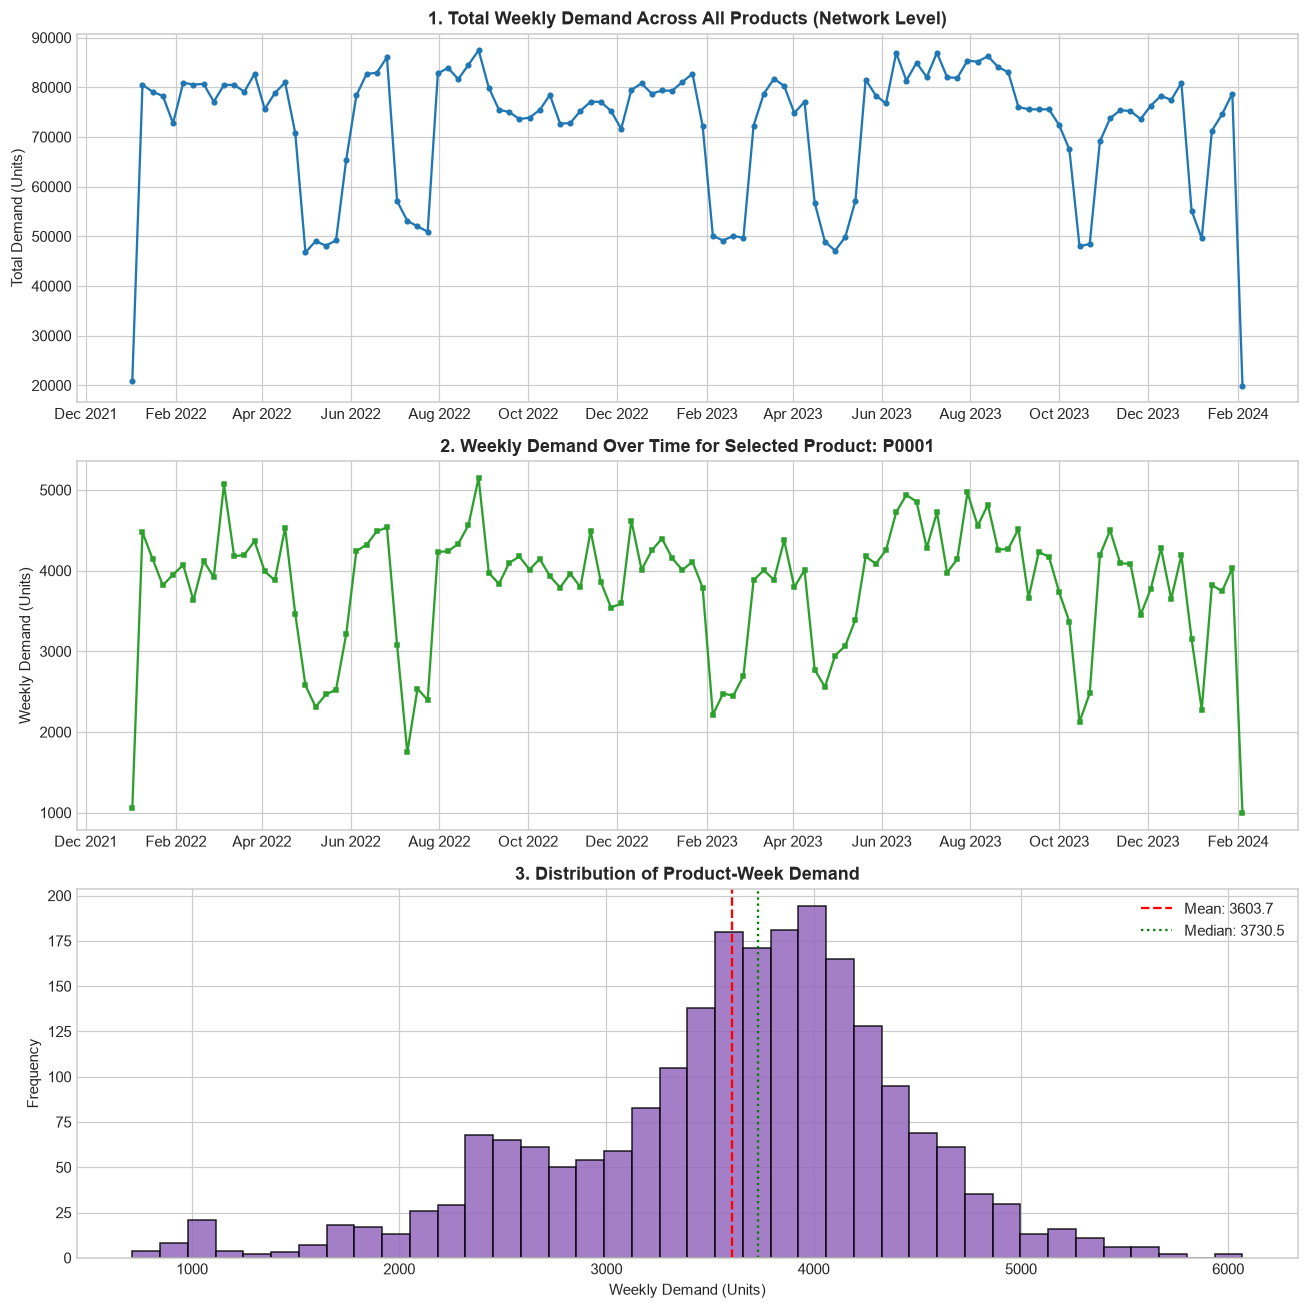

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12))

total_weekly = weekly_df.groupby('Week_Ending')['Weekly_Demand'].sum().reset_index()
axes[0].plot(total_weekly['Week_Ending'], total_weekly['Weekly_Demand'], color='#1f77b4', marker='o', markersize=3)
axes[0].set_title('1. Total Weekly Demand Across All Products (Network Level)', fontweight='bold')
axes[0].set_ylabel('Total Demand (Units)')
axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

selected_product = sorted(weekly_df['Product ID'].unique())[0]
p_data = weekly_df[weekly_df['Product ID'] == selected_product]
axes[1].plot(p_data['Week_Ending'], p_data['Weekly_Demand'], color='#2ca02c', marker='s', markersize=3)
axes[1].set_title(f'2. Weekly Demand Over Time for Selected Product: {selected_product}', fontweight='bold')
axes[1].set_ylabel('Weekly Demand (Units)')
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

axes[2].hist(weekly_df['Weekly_Demand'], bins=40, color='#9467bd', edgecolor='black', alpha=0.85)
axes[2].axvline(weekly_df['Weekly_Demand'].mean(), color='red', linestyle='--', label=f"Mean: {weekly_df['Weekly_Demand'].mean():.1f}")
axes[2].axvline(weekly_df['Weekly_Demand'].median(), color='green', linestyle=':', label=f"Median: {weekly_df['Weekly_Demand'].median():.1f}")
axes[2].set_title('3. Distribution of Product-Week Demand', fontweight='bold')
axes[2].set_xlabel('Weekly Demand (Units)')
axes[2].set_ylabel('Frequency')
axes[2].legend()

plt.tight_layout()
plt.show()

## 7. Moving-Average Baseline
Compute the 4-week trailing moving average per product with `shift(1)` via `compute_moving_average_baseline` and evaluate on the chronological 80/20 test split.

In [6]:
weekly_df['Moving_Average_4W'] = compute_moving_average_baseline(weekly_df, window=4)
ma_train_df, ma_test_df, ma_split = chronological_week_split(weekly_df, train_ratio=0.80)

baseline_metrics = evaluate_regression_metrics(ma_test_df['Weekly_Demand'], ma_test_df['Moving_Average_4W'])
print(f"Chronological Split: Train {ma_split['train_start']}..{ma_split['train_end']} ({ma_split['train_weeks_count']} wks) | Test {ma_split['test_start']}..{ma_split['test_end']} ({ma_split['test_weeks_count']} wks)")
print(f"4-Week Moving Average Baseline (N={baseline_metrics['n_samples']}): MAE={baseline_metrics['mae']:.2f}, RMSE={baseline_metrics['rmse']:.2f}, WAPE={baseline_metrics['wape']:.2f}%, R2={baseline_metrics['r2']:.4f}")

Chronological Split: Train 2022-01-02..2023-09-03 (88 wks) | Test 2023-09-10..2024-02-04 (22 wks)
4-Week Moving Average Baseline (N=440): MAE=663.63, RMSE=880.25, WAPE=19.57%, R2=-0.1101


## 8. Feature Engineering (Leakage-Safe)
Fit `product_code` mapping on training products only and build lagged (`lag_1`..`lag_4`), trailing rolling (`roll_mean_4`, `roll_std_4`, `roll_mean_8` on `shift(1)`), and calendar features (`week_of_year`, `month`). Future `Units Sold`, `Inventory Level`, or unguaranteed external variables are excluded.

In [7]:
train_product_mapping = build_product_mapping(ma_train_df['Product ID'])
featured_df, product_mapping = build_lag_and_calendar_features(
    weekly_df,
    product_mapping=train_product_mapping,
    drop_na=True,
)
print(f'Features used ({len(FEATURE_COLUMNS)}): {FEATURE_COLUMNS}')
print(f'Feature-complete dataset rows: {len(featured_df):,} (first 4 weeks per product dropped due to 4-week lag requirement)')
display(featured_df[['Product ID', 'Week_Ending', 'Weekly_Demand'] + FEATURE_COLUMNS].head(6))

Features used (10): ['product_code', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'roll_mean_4', 'roll_std_4', 'roll_mean_8', 'week_of_year', 'month']
Feature-complete dataset rows: 2,120 (first 4 weeks per product dropped due to 4-week lag requirement)


,Product ID,Week_Ending,Weekly_Demand,product_code,lag_1,lag_2,lag_3,lag_4,roll_mean_4,roll_std_4,roll_mean_8,week_of_year,month
0,P0001,2022-01-30,3952,0,3818.0,4143.0,4476.0,1057.0,3373.50,1567.523418,3373.500000,4,1
1,P0001,2022-02-06,4071,0,3952.0,3818.0,4143.0,4476.0,4097.25,285.553702,3489.200000,5,2
2,P0001,2022-02-13,3632,0,4071.0,3952.0,3818.0,4143.0,3996.00,142.424249,3586.166667,6,2
3,P0001,2022-02-20,4121,0,3632.0,4071.0,3952.0,3818.0,3868.25,188.379714,3592.714286,7,2
4,P0001,2022-02-27,3919,0,4121.0,3632.0,4071.0,3952.0,3944.00,219.746824,3658.750000,8,2
5,P0001,2022-03-06,5070,0,3919.0,4121.0,3632.0,4071.0,3935.75,219.965717,4016.500000,9,3


## 9. Chronological Model Training and Validation
Split `featured_df` by the identical 80/20 week boundary (keeping all products in the same week together) and fit `RandomForestRegressor` with documented parameters.

In [8]:
rf_train_df = featured_df[featured_df['Week_Ending'] < pd.Timestamp(ma_split['split_date'])].copy().reset_index(drop=True)
rf_test_df = featured_df[featured_df['Week_Ending'] >= pd.Timestamp(ma_split['split_date'])].copy().reset_index(drop=True)

assert len(rf_test_df) == len(ma_test_df), 'Test set mismatch between baseline and Random Forest!'
print(f'RF Train rows: {len(rf_train_df):,} ({rf_train_df["Week_Ending"].nunique()} weeks) | RF Test rows: {len(rf_test_df):,} ({rf_test_df["Week_Ending"].nunique()} weeks)')
print(f'RandomForestRegressor config: {DEFAULT_RF_PARAMS}')

rf_model = train_random_forest(rf_train_df, feature_cols=FEATURE_COLUMNS, params=DEFAULT_RF_PARAMS)
rf_test_df['RF_Predicted'] = predict_random_forest(rf_model, rf_test_df, feature_cols=FEATURE_COLUMNS)
rf_test_df = rf_test_df.rename(columns={'Weekly_Demand': 'Actual_Demand', 'Moving_Average_4W': 'MA_Predicted'})

RF Train rows: 1,680 (84 weeks) | RF Test rows: 440 (22 weeks)
RandomForestRegressor config: {'n_estimators': 200, 'max_depth': 10, 'min_samples_leaf': 3, 'random_state': 42, 'n_jobs': -1}


## 10. Random Forest Evaluation
Evaluate rolling one-week-ahead Random Forest predictions using MAE, RMSE, WAPE, and R² alongside feature importances.

In [9]:
rf_metrics = evaluate_regression_metrics(rf_test_df['Actual_Demand'], rf_test_df['RF_Predicted'])
print(f"Random Forest (All {rf_metrics['n_samples']} test rows): MAE={rf_metrics['mae']:.2f}, RMSE={rf_metrics['rmse']:.2f}, WAPE={rf_metrics['wape']:.2f}%, R2={rf_metrics['r2']:.4f}")

importances = pd.DataFrame({
    'Feature': FEATURE_COLUMNS,
    'Importance': rf_model.feature_importances_,
}).sort_values('Importance', ascending=False).reset_index(drop=True)
display(importances)

Random Forest (All 440 test rows): MAE=569.37, RMSE=870.01, WAPE=16.79%, R2=-0.0844


,Feature,Importance
0,lag_1,0.589827
1,lag_4,0.078711
2,week_of_year,0.070096
3,roll_std_4,0.061043
4,roll_mean_8,0.051764
5,product_code,0.048227
6,lag_2,0.036388
7,lag_3,0.027226
8,roll_mean_4,0.024963
9,month,0.011755


## 11. Baseline versus Random Forest Comparison
Compare both models on identical eligible test records (440 rows), and also inspect sensitivity on the 420 full 7-day test weeks (excluding the final 2-day partial week `2024-02-04`).

=== Overall Comparison (All 440 Eligible Test Product-Weeks) ===


,Model,Evaluated_Rows,MAE,RMSE,WAPE_Pct,R2
0,Moving Average (4W),440,663.629545,880.249896,19.565193,-0.110128
1,Random Forest,440,569.368535,870.009411,16.786180,-0.084449


=== Full 7-Day Weeks Sensitivity (420 Rows, Excluding 2-Day Partial Week 2024-02-04) ===


,Model,Evaluated_Rows,MAE,RMSE,WAPE_Pct,R2
0,Moving Average (4W),420,579.436905,724.632757,16.527165,-0.181023
1,Random Forest,420,456.573314,615.913576,13.022751,0.146778


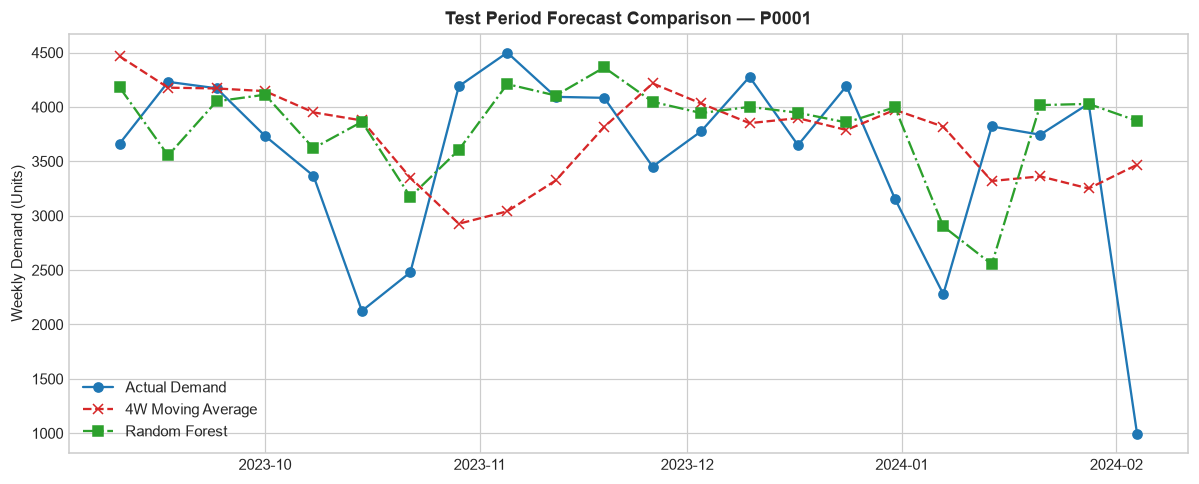

In [10]:
comparison_all = compare_models(rf_test_df, actual_col='Actual_Demand')
print('=== Overall Comparison (All 440 Eligible Test Product-Weeks) ===')
display(comparison_all)

last_test_week = rf_test_df['Week_Ending'].max()
full_weeks_test = rf_test_df[rf_test_df['Week_Ending'] < last_test_week].copy()
comparison_full = compare_models(full_weeks_test, actual_col='Actual_Demand')
print(f'=== Full 7-Day Weeks Sensitivity (420 Rows, Excluding 2-Day Partial Week {last_test_week.strftime("%Y-%m-%d")}) ===')
display(comparison_full)

p_eval = rf_test_df[rf_test_df['Product ID'] == selected_product].sort_values('Week_Ending')
plt.figure(figsize=(11, 4.5))
plt.plot(p_eval['Week_Ending'], p_eval['Actual_Demand'], marker='o', label='Actual Demand', color='#1f77b4')
plt.plot(p_eval['Week_Ending'], p_eval['MA_Predicted'], marker='x', linestyle='--', label='4W Moving Average', color='#d62728')
plt.plot(p_eval['Week_Ending'], p_eval['RF_Predicted'], marker='s', linestyle='-.', label='Random Forest', color='#2ca02c')
plt.title(f'Test Period Forecast Comparison — {selected_product}', fontweight='bold')
plt.ylabel('Weekly Demand (Units)')
plt.legend()
plt.tight_layout()
plt.show()

## 12. Product-Level Evaluation
Compute per-product MAE, RMSE, WAPE, R², and explicit reliability tiers (`Good`: WAPE <= 15%, `Moderate`: <= 25%, `Low`: > 25%) via `evaluate_by_product`.

In [11]:
product_eval_df = evaluate_by_product(rf_test_df, actual_col='Actual_Demand', pred_col='RF_Predicted')
print('Reliability distribution across 20 products:')
print(product_eval_df['Reliability_Label'].value_counts().to_dict())
display(product_eval_df)

Reliability distribution across 20 products:
{'Moderate': 17, 'Good': 3}


,Product ID,Test_Weeks,Mean_Actual,Mean_Predicted,MAE,RMSE,WAPE_Pct,R2,Reliability_Label,Reliability_Message
0,P0018,22,3280.636364,3472.507425,414.781969,710.212004,12.643339,-0.417322,Good,Previous forecasts were usually close to actua...
1,P0010,22,3613.727273,3899.149713,462.154235,812.476408,12.788852,-0.124902,Good,Previous forecasts were usually close to actua...
2,P0019,22,3259.727273,3447.193880,430.628729,709.834855,13.210575,-0.373648,Good,Previous forecasts were usually close to actua...
3,P0008,22,3429.681818,3805.194048,515.544864,828.156765,15.031857,-0.406741,Moderate,"Forecasts follow typical demand, though weekly..."
4,P0011,22,3311.500000,3611.082176,506.726068,802.613404,15.302010,-0.220059,Moderate,"Forecasts follow typical demand, though weekly..."
5,P0009,22,4009.954545,4046.009849,623.725030,917.574010,15.554416,-0.008018,Moderate,"Forecasts follow typical demand, though weekly..."
6,P0015,22,3337.636364,3627.506903,525.714441,834.585897,15.751100,-0.419086,Moderate,"Forecasts follow typical demand, though weekly..."
7,P0004,22,3781.227273,3989.226319,596.024169,929.035289,15.762717,-0.089408,Moderate,"Forecasts follow typical demand, though weekly..."
8,P0001,22,3545.954545,3818.660856,595.615079,870.989305,16.797031,-0.064943,Moderate,"Forecasts follow typical demand, though weekly..."
9,P0007,22,3659.318182,3905.744705,617.126130,913.113252,16.864511,0.015321,Moderate,"Forecasts follow typical demand, though weekly..."


## 13. Future Weekly Demand Forecasting (1, 2, 4, 8 Weeks)
Evaluate recursive multi-step forecasting separately across horizons 1–4 and 8 on held-out test origins using prior model predictions as lag inputs.
> **Partial-Week Disclosure**: Because the final observed week (`2024-02-04`) only covers 2 operating days (`2024-01-29`–`2024-01-30`), its lower raw total enters `lag_1` and depresses early post-cutoff predictions; this is preserved transparently rather than altered.

In [12]:
# Split training weeks into fit (62 wks) and validation (22 wks) to calibrate per-horizon uncertainty without touching test
train_unique_weeks = sorted(rf_train_df['Week_Ending'].unique())
fit_weeks_set = set(train_unique_weeks[:62])
cal_weeks_list = train_unique_weeks[62:]
test_weeks_list = sorted(rf_test_df['Week_Ending'].unique())

fit_only_df = rf_train_df[rf_train_df['Week_Ending'].isin(fit_weeks_set)].copy()
cal_model = train_random_forest(fit_only_df, feature_cols=FEATURE_COLUMNS, params=DEFAULT_RF_PARAMS)

horizon_eval_df, calibrated_step_hw = evaluate_recursive_horizons(
    model=rf_model,
    weekly_df=weekly_df,
    test_weeks=test_weeks_list,
    product_mapping=product_mapping,
    horizons=HORIZON_OPTIONS,
    feature_cols=FEATURE_COLUMNS,
    cal_model=cal_model,
    cal_weeks=cal_weeks_list,
    alpha=0.20,
)
display(horizon_eval_df[horizon_eval_df['Horizon_Weeks'].isin([1, 2, 4, 8])])

,Horizon_Weeks,Evaluated_Rows,MAE,RMSE,WAPE_Pct,R2,Conformal_80_HalfWidth,Test_Empirical_Coverage,Mean_Interval_Width
0,1,440,569.368535,870.009411,16.786180,-0.084449,732.041540,0.752273,1464.083079
1,2,420,681.479899,980.296358,20.201104,-0.339336,932.027531,0.740476,1864.055062
3,4,380,672.987330,939.209380,20.204656,-0.164111,946.971060,0.739474,1893.942120
4,8,300,587.521078,882.216309,17.122871,0.014882,934.756159,0.806667,1869.512318


## 14. Forecast Uncertainty & Calibrated Prediction Intervals
Calibrate an 80% split-conformal prediction interval on validation residuals (`calibrate_conformal_interval`) and verify empirical coverage on the held-out test set, then generate a 4-week future forecast with step-specific calibrated bounds.

In [13]:
val_only_df = rf_train_df[rf_train_df['Week_Ending'].isin(cal_weeks_list)].copy()
conformal_1w = calibrate_conformal_interval(fit_only_df, val_only_df, feature_cols=FEATURE_COLUMNS, alpha=0.20, params=DEFAULT_RF_PARAMS)
cal_test_preds = predict_random_forest(conformal_1w['model'], rf_test_df, feature_cols=FEATURE_COLUMNS)
cov_all = evaluate_interval_coverage(
    rf_test_df['Actual_Demand'].values,
    np.maximum(0.0, cal_test_preds - conformal_1w['half_width']),
    cal_test_preds + conformal_1w['half_width'],
)
cov_full = evaluate_interval_coverage(
    full_weeks_test['Actual_Demand'].values,
    np.maximum(0.0, predict_random_forest(conformal_1w['model'], full_weeks_test, FEATURE_COLUMNS) - conformal_1w['half_width']),
    predict_random_forest(conformal_1w['model'], full_weeks_test, FEATURE_COLUMNS) + conformal_1w['half_width'],
)
print(f"80% Nominal Split-Conformal Half-Width (calibrated on N={conformal_1w['calibration_n']} validation rows): +/- {conformal_1w['half_width']:.2f} units")
print(f"Held-out Empirical Coverage: {cov_all['empirical_coverage']*100:.1f}% (all 440 rows) | {cov_full['empirical_coverage']*100:.1f}% (420 full 7-day weeks)")

future_4w_df = forecast_future_weeks(
    model=rf_model,
    weekly_df=weekly_df,
    product_mapping=product_mapping,
    horizon=4,
    feature_cols=FEATURE_COLUMNS,
    interval_half_width_by_step=calibrated_step_hw,
)
print('Sample 4-week ahead recursive forecast with step-calibrated 80% bounds (not a guarantee):')
display(future_4w_df.head(8))

80% Nominal Split-Conformal Half-Width (calibrated on N=440 validation rows): +/- 732.04 units
Held-out Empirical Coverage: 75.2% (all 440 rows) | 78.8% (420 full 7-day weeks)


Sample 4-week ahead recursive forecast with step-calibrated 80% bounds (not a guarantee):


,Product ID,Forecast_Step,Week_Ending,Predicted_Demand,Lower_Bound,Upper_Bound
0,P0001,1,2024-02-11,2113.706826,1381.665286,2845.748365
1,P0001,2,2024-02-18,1962.051533,1030.024002,2894.079064
2,P0001,3,2024-02-25,1880.933626,941.461319,2820.405932
3,P0001,4,2024-03-03,2756.525876,1809.554816,3703.496936
4,P0002,1,2024-02-11,2126.424837,1394.383298,2858.466377
5,P0002,2,2024-02-18,2231.405610,1299.378079,3163.433141
6,P0002,3,2024-02-25,2381.919862,1442.447555,3321.392169
7,P0002,4,2024-03-03,3324.907036,2377.935976,4271.878096


## 15. Inventory Analysis
Verify `Inventory Level` semantics (start-of-day opening stock where `Units Sold <= Inventory Level`), compute end-of-dataset closing stock (`Inventory Level - Units Sold` on `2024-01-30`), and summarize movement tiers across products and categories. Outputs reflect the uploaded historical snapshot, not live stock.

In [14]:
inv_semantics = verify_inventory_semantics(processed_df)
print('Inventory Field Verification:', inv_semantics)

product_inventory_df = analyze_product_inventory(processed_df, weekly_df)
category_inventory_df = summarize_category_inventory(product_inventory_df)

print('\nCategory Summary (Historical Dataset Snapshot):')
display(category_inventory_df)
print('\nProduct Inventory & Movement Summary (Top 10 by Avg Weekly Demand):')
display(product_inventory_df[['Product ID', 'Category', 'Movement_Class', 'Avg_Weekly_Demand', 'Latest_Closing_Stock', 'Estimated_Weeks_of_Cover', 'Stock_Position']].head(10))

Inventory Field Verification: {'has_full_inventory_columns': True, 'sold_exceeds_opening_inventory_rows': 0, 'negative_unexplained_stock_delta_rows': 0, 'verified_opening_stock_semantics': True, 'latest_snapshot_date': '2024-01-30'}

Category Summary (Historical Dataset Snapshot):


,Category,Product_Count,Total_Historical_Demand,Avg_Product_Weekly_Demand,Latest_Closing_Stock
0,Groceries,6,2317296,3511.054545,8078
1,Toys,4,1590328,3614.381818,4774
2,Furniture,4,1497631,3403.706818,2704
3,Clothing,3,1271359,3852.603030,2332
4,Electronics,3,1251490,3792.393939,2736



Product Inventory & Movement Summary (Top 10 by Avg Weekly Demand):


,Product ID,Category,Movement_Class,Avg_Weekly_Demand,Latest_Closing_Stock,Estimated_Weeks_of_Cover,Stock_Position
0,P0009,Clothing,Fast-Moving,4093.854545,548,0.133859,Low Inventory
1,P0013,Toys,Fast-Moving,4008.136364,1793,0.447340,Low Inventory
2,P0004,Electronics,Fast-Moving,3986.409091,1000,0.250852,Low Inventory
3,P0007,Groceries,Fast-Moving,3973.536364,1462,0.367934,Low Inventory
4,P0002,Clothing,Fast-Moving,3871.390909,976,0.252106,Low Inventory
5,P0010,Furniture,Moderate-Moving,3836.945455,674,0.175661,Low Inventory
6,P0001,Electronics,Moderate-Moving,3785.881818,1388,0.366625,Low Inventory
7,P0006,Toys,Moderate-Moving,3721.318182,589,0.158277,Low Inventory
8,P0005,Groceries,Moderate-Moving,3714.345455,2252,0.606298,Low Inventory
9,P0008,Electronics,Moderate-Moving,3604.890909,348,0.096536,Low Inventory


## 16. Stockout-Risk Estimation
Compare latest historical closing stock against next-week forecasted demand to identify products with less than 1 week of estimated stock cover (conditional on the uploaded historical snapshot).

In [15]:
recommendations = generate_replenishment_recommendations(
    inventory_df=product_inventory_df,
    forecast_df=future_4w_df,
    product_eval_df=product_eval_df,
    lead_time_weeks=1.0,
    safety_stock_weeks=0.5,
)
recs_df = pd.DataFrame(recommendations)
print('Stockout-risk breakdown across 20 products (historical snapshot):')
print(recs_df['stock_status'].value_counts().to_dict())
display(recs_df[['product_id', 'week_ending', 'available_stock', 'predicted_demand', 'estimated_weeks_of_cover', 'stock_status', 'reliability_label']].head(10))

Stockout-risk breakdown across 20 products (historical snapshot):
{'High Stockout Risk': 19, 'Low Stock / Reorder Soon': 1}


,product_id,week_ending,available_stock,predicted_demand,estimated_weeks_of_cover,stock_status,reliability_label
0,P0001,2024-02-11,1388,2113.71,0.64,High Stockout Risk,Moderate
1,P0002,2024-02-11,976,2126.42,0.39,High Stockout Risk,Moderate
2,P0003,2024-02-11,808,2061.61,0.30,High Stockout Risk,Moderate
3,P0004,2024-02-11,1000,2297.38,0.37,High Stockout Risk,Moderate
4,P0005,2024-02-11,2252,2105.35,1.04,Low Stock / Reorder Soon,Moderate
5,P0006,2024-02-11,589,2019.43,0.22,High Stockout Risk,Moderate
6,P0007,2024-02-11,1462,2044.53,0.68,High Stockout Risk,Moderate
7,P0008,2024-02-11,348,2163.89,0.14,High Stockout Risk,Moderate
8,P0009,2024-02-11,548,2298.67,0.20,High Stockout Risk,Moderate
9,P0010,2024-02-11,674,2152.17,0.27,High Stockout Risk,Good


## 17. Replenishment Recommendations
Compute indicative suggested order quantities (`max(0, target_stock - available_stock - confirmed_incoming)`) under explicit, configurable assumptions (1.0-week lead time + 0.5-week safety buffer, 0 confirmed incoming stock unless supplied) with plain shopkeeper explanations.

In [16]:
print('Assumptions:', recs_df['assumptions'].iloc[0])
display(recs_df[['product_id', 'predicted_demand', 'lower_bound', 'upper_bound', 'available_stock', 'suggested_order_quantity', 'explanation']])

Assumptions: Indicative calculation based on uploaded historical snapshot (not real-time live stock); assumes 1.0-week replenishment lead time, 0.5-week safety buffer, 0 confirmed incoming stock unless supplied, and no fixed supplier pack size / MOQ.


,product_id,predicted_demand,lower_bound,upper_bound,available_stock,suggested_order_quantity,explanation
0,P0001,2113.71,1381.67,2845.75,1388,1879,"This product may run out soon: 1,388 units lef..."
1,P0002,2126.42,1394.38,2858.47,976,2798,This product may run out soon: 976 units left ...
2,P0003,2061.61,1329.57,2793.65,808,3247,This product may run out soon: 808 units left ...
3,P0004,2297.38,1565.34,3029.42,1000,3032,"This product may run out soon: 1,000 units lef..."
4,P0005,2105.35,1373.31,2837.40,2252,983,Stock covers about 1.0 weeks of expected deman...
5,P0006,2019.43,1287.39,2751.47,589,3386,This product may run out soon: 589 units left ...
6,P0007,2044.53,1312.49,2776.57,1462,1744,"This product may run out soon: 1,462 units lef..."
7,P0008,2163.89,1431.85,2895.93,348,3463,This product may run out soon: 348 units left ...
8,P0009,2298.67,1566.63,3030.71,548,3542,This product may run out soon: 548 units left ...
9,P0010,2152.17,1420.13,2884.21,674,3122,This product may run out soon: 674 units left ...


## 18. Prototype Summary and Limitations
- **End-to-End Parity**: Notebook 01 directly calls reusable `backend` modules (`load_csv`, `validate_or_raise`, `preprocess_dataframe`, `aggregate_weekly_demand`, `feature_engineering`, `demand_forecaster`, `model_evaluation`, `forecasting_service`, `inventory_analysis`, `replenishment_service`).
- **Key Limitations**:
  1. `sales_data.csv` is synthetic; results do not prove real-world kirana-shop performance.
  2. The final week (`2024-02-04`) contains only 2 days of data (`2024-01-29` to `2024-01-30`), causing a large downward demand jump that neither model could anticipate from full-week training lags.
  3. Supplier lead times in the dataset vary empirically from 1–5 days and no pack size/MOQ is provided, so reorder quantities are indicative decision support only.